**1. Import all the required libraries**

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix, recall_score, precision_score
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

**2.Loading the datasets and preprosessing**

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

#set the path
data_folder = '../MISC/data'
train_file = os.path.join(data_folder, 'train_deepclean.csv')
test_file = os.path.join(data_folder, 'test_deepclean.csv')
manual_file = os.path.join(data_folder, 'manual_annotation_200.csv')

print("loading the dataset")
try:
    train_df = pd.read_csv(train_file)
    test_df = pd.read_csv(test_file)
    manual_df = pd.read_csv(manual_file, encoding='latin-1')
    print("successfully loaded the dataset")
except FileNotFoundError as e:
    raise FileNotFoundError(f"error in '{data_folder}'")

#use the same deep clean logic in the manual dataset("manual_annotation_200")
def heavy_clean_text(text):
    if not isinstance(text, str):
        return ""

    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'@\w+', '', text)

    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = word_tokenize(text)
    stop_words = set(stopwords.words('english'))
    #wordNet word form restoration
    lemmatizer = WordNetLemmatizer()

    clean_tokens = []
    for word in tokens:
        if word not in stop_words and len(word) > 1:
            clean_word = lemmatizer.lemmatize(word)
            clean_tokens.append(clean_word)

    text = ' '.join(clean_tokens)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

#extract X and y
def prepare_xy_cleaned(df):
    """use in the train\test, already deep clean it"""
    df['cleaned_text'] = df['cleaned_text'].fillna('').astype(str)
    return df['cleaned_text'], df['toxic']

#about the train\test, already deep clean it
X_train, y_train = prepare_xy_cleaned(train_df)
X_test, y_test = prepare_xy_cleaned(test_df)

print("clean the OOD dataset")
manual_df['new_cleaned_text'] = manual_df['cleaned_text'].apply(heavy_clean_text)
X_manual = manual_df['new_cleaned_text']
y_manual = manual_df['toxic']
print("success to clean the manual dataset")

[nltk_data] Downloading package punkt to /Users/eddieduck/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/eddieduck/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/eddieduck/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


loading the dataset
successfully loaded the dataset
clean the OOD dataset
success to clean the manual dataset


**3.Feature extraction and model training**

In [3]:
#using ngram_range=(1, 2) to capture word order
vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
X_manual_tfidf = vectorizer.transform(X_manual)

print("beginning the training")
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
print("successfully trained the model")


beginning the training
successfully trained the model


**4.Evaluation and confusion matrix visualization**


Part One: In-Distribution Performance of the Test set

 test_deepclean.csv evaluate result
Accuracy:        0.9265
Precision (1):   0.9524
Recall (1):      0.1818
F1-Toxic (1):    0.3053
Macro F1-Score:  0.6333


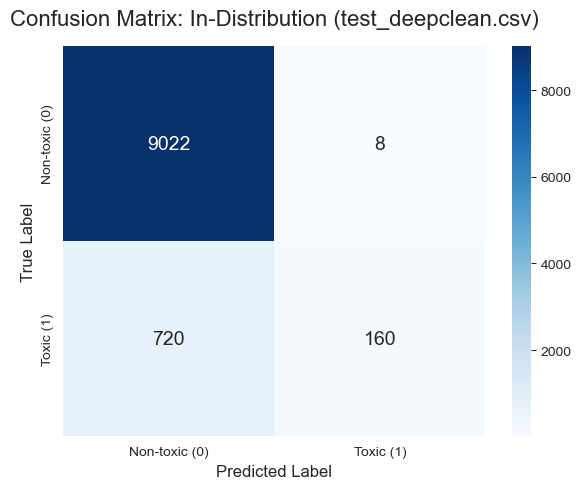


Part Two: Performance of Manual Label Sets (Out-of-Distribution

 manual_annotation_200.csv evaluate result
Accuracy:        0.6207
Precision (1):   0.5000
Recall (1):      0.0341
F1-Toxic (1):    0.0638
Macro F1-Score:  0.4130


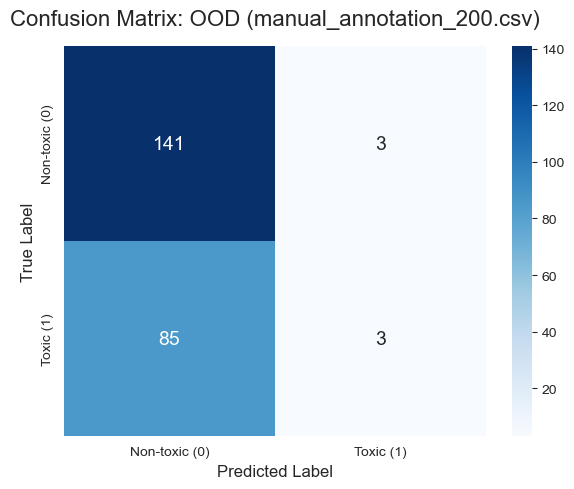

In [6]:
def evaluate_and_plot(X, y, dataset_name, title_suffix):
    #predict
    y_pred = nb_model.predict(X)

    #compute the evaluate data
    acc = accuracy_score(y, y_pred)
    f1_tox = f1_score(y, y_pred)
    macro_f1 = f1_score(y, y_pred, average='macro')
    recall_tox = recall_score(y, y_pred)
    precision_tox = precision_score(y, y_pred)

    print(f"\n=========================================")
    print(f" {dataset_name} evaluate result")
    print(f"=========================================")
    print(f"Accuracy:        {acc:.4f}")
    print(f"Precision (1):   {precision_tox:.4f}")
    print(f"Recall (1):      {recall_tox:.4f}")
    print(f"F1-Toxic (1):    {f1_tox:.4f}")
    print(f"Macro F1-Score:  {macro_f1:.4f}")

    #plot the confusion matrix
    cm = confusion_matrix(y, y_pred)
    plt.figure(figsize=(6, 5))
    ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                     xticklabels=['Non-toxic (0)', 'Toxic (1)'],
                     yticklabels=['Non-toxic (0)', 'Toxic (1)'],
                     annot_kws={"size": 14})
    plt.title(f"Confusion Matrix: {title_suffix}", fontsize=16, pad=15)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    plt.show()

    #return the dictionary for use in the next chart
    return {'Accuracy': acc, 'F1 macro': macro_f1, 'F1 toxic': f1_tox,
            'Precision toxic': precision_tox, 'Recall toxic': recall_tox}

print("\nPart One: In-Distribution Performance of the Test set")
results_test = evaluate_and_plot(X_test_tfidf, y_test, "test_deepclean.csv", "In-Distribution (test_deepclean.csv)")

print("\nPart Two: Performance of Manual Label Sets (Out-of-Distribution")
results_manual = evaluate_and_plot(X_manual_tfidf, y_manual, "manual_annotation_200.csv", "OOD (manual_annotation_200.csv)")

**5.Generate a comparison chart of the plummeting performance of Distribution Shift**

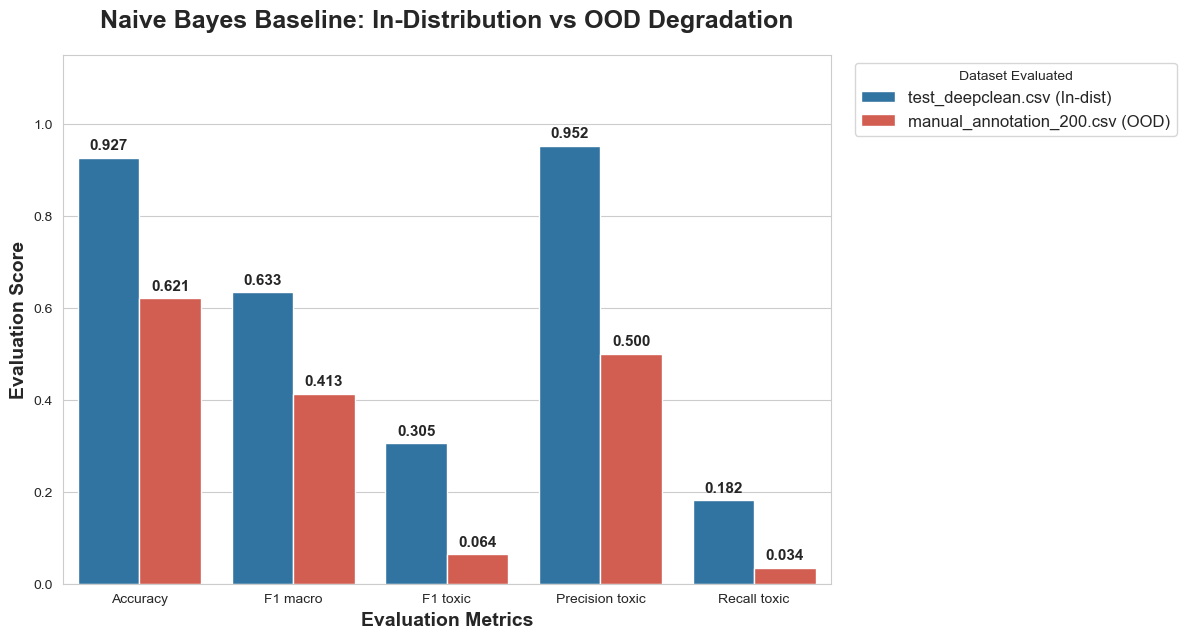

In [7]:
#use the result
data = {
    'Metric': list(results_test.keys()),
    'test_deepclean.csv (In-dist)': list(results_test.values()),
    'manual_annotation_200.csv (OOD)': list(results_manual.values())
}
df_results = pd.DataFrame(data)

#convert data format
df_melted = df_results.melt(id_vars='Metric', var_name='Dataset', value_name='Score')

#draw a two-color bar chart
plt.figure(figsize=(12, 6.5))
colors = ['#1f77b4', '#e74c3c']
ax = sns.barplot(x='Metric', y='Score', hue='Dataset', data=df_melted, palette=colors)

#add the label in the bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=4, fontsize=11, fontweight='bold')


plt.title('Naive Bayes Baseline: In-Distribution vs OOD Degradation', fontsize=18, pad=20, fontweight='bold')
plt.ylabel('Evaluation Score', fontsize=14, fontweight='bold')
plt.xlabel('Evaluation Metrics', fontsize=14, fontweight='bold')
plt.ylim(0, 1.15)
plt.legend(title='Dataset Evaluated', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=12)

plt.tight_layout()
plt.savefig('baseline_distribution_shift.png', dpi=300, bbox_inches='tight')
plt.show()

**6.Save the model**

In [9]:
import joblib

#save model in folder
save_dir = '../MISC/saved_model'
os.makedirs(save_dir, exist_ok=True)

#vectorizers and models
joblib.dump(vectorizer, os.path.join(save_dir, 'tfidf_vectorizer.pkl'))
joblib.dump(nb_model, os.path.join(save_dir, 'naive_bayes_model.pkl'))
print("already saved_models")

already saved_models


**7.Qualitative evaluation error case extractor**

In [10]:
import pandas as pd

def extract_error_patterns(X_raw, y_true, X_tfidf, model, dataset_name, num_examples=5):
    """
    Extract and print the specific sentences where the model classification is incorrect
    """
    print(f"\nanalyse the {dataset_name} classification error...")

    #obtain the prediction results of the model
    y_pred = model.predict(X_tfidf)

    #merge the original text, real labels and predicted labels
    df_errors = pd.DataFrame({
        'Comment': X_raw,
        'Actual_Label': y_true,
        'Predicted_Label': y_pred
    })

    #filter False Negatives (actual malice =1, predicted normal =0)
    fn_df = df_errors[(df_errors['Actual_Label'] == 1) & (df_errors['Predicted_Label'] == 0)]

    #filter False Positives (actual normal =0, predicted malicious =1)
    fp_df = df_errors[(df_errors['Actual_Label'] == 0) & (df_errors['Predicted_Label'] == 1)]

    print("-" * 60)
    print(f"[False Negatives]---Typical implicit malice/irony")
    print(f"The total number of underreports: {len(fn_df)} ")
    print("-" * 60)
    #see the example
    for idx, text in enumerate(fn_df['Comment'].sample(min(num_examples, len(fn_df)), random_state=42)):
        print(f"[wrong case {idx+1}]: {text}\n")

    print("-" * 60)
    print(f"[False Positives]---Typical overly sensitive/normal interjections")
    print(f"The total number of false positives : {len(fp_df)} ")
    print("-" * 60)
    for idx, text in enumerate(fp_df['Comment'].sample(min(num_examples, len(fp_df)), random_state=42)):
        print(f"[wrong case {idx+1}]: {text}\n")

#perform the analysis (taking the test.csv set as an example)
print("\n" + "="*20)
print("Part One: Classic Error Analysis of the test Set (test_deepclean.csv)")
print("="*20)
extract_error_patterns(test_df['cleaned_text'], y_test, X_test_tfidf, nb_model, "test_deepclean.csv(In-Distribution)", num_examples=3)

#perform the analysis (taking the OOD manual annotation set as an example)
print("\n" + "="*20)
print("Part Two: Classic Error Analysis of Manual Annotation Set (manual_annotation_200.csv)")
print("="*20)
extract_error_patterns(manual_df['cleaned_text'], y_manual, X_manual_tfidf, nb_model, "OOD Manual annotation set (manual_annotation_200.csv)", num_examples=3)


Part One: Classic Error Analysis of the test Set (test_deepclean.csv)

analyse the test_deepclean.csv(In-Distribution) classification error...
------------------------------------------------------------
[False Negatives]---Typical implicit malice/irony
The total number of underreports: 720 
------------------------------------------------------------
[wrong case 1]: silly story run pretty much anyplace one go buy stock

[wrong case 2]: really going portland look racial demographic portland california portland mostly white whereas california largest minority population u obvious everyone know oregon history portlanders want californian coming californian sometimes white portlanders racist yeah said

[wrong case 3]: tent left along cooler gear trash obviously individual responsible lambda chi alpha acted like spoiled brat thinking mom would clean one stupid enough leave personalized calling card joe average left mess like federal park bet would severe fine possibly jail time fraternity

**8.Command-line single-sentence test（CLI testing）**

After the model is trained and saved, you can directly input any text in the terminal for real‑time toxicity detection:

```
python test_client.py --text "Shut up you idiot"
```



**9.Launch the visual web demo (Gradio Demo)**

Start a web UI that is friendly to non‑technical reviewers:

```
python web_demo.py
```

After running, click the local link output in the terminal (e.g., `http://127.0.0.1:7860`) to experience the complete data cleaning and real‑time classification pipeline in your browser.